# Time Series V2

Imagine our class is helping a student bike club plan a ride across Seattle's Fremont Bridge. Maya wants to avoid the busiest traffic. Luis asks whether a quiet-looking hour means the bridge was empty or the counter stopped working. Later, the club asks what an air-quality sensor can tell us about choosing a day outdoors.

A **time series** connects measurements of a process to when they happened. To help them choose, we need to know when traffic is busiest, what changes when we summarize it, and whether gaps in the measurements could affect our answer. We will start with six made-up readings that are small enough to check by hand, then use those tools to explore the bridge and air-quality records.

By the end, you can:

- Parse and sort a time index; select dates with `.loc`.
- Resample hourly measurements into daily, weekly, and monthly summaries and visualize the changes.
- Separate a timeline from a recurring weekday or seasonal pattern.
- Check missing observations and explain what interpolation assumes.
- Investigate a dataset's collection setting and assess competing claims.

At each **Your turn**, try the code yourself, then compare your reasoning with a partner.

## What does one row mean?

Luis wants to know what each count covers: one moment, an hour, or a whole day? Before comparing rows, identify both the time label and the measurement it describes.

| Familiar example | What the time tells us | What the value measures |
| --- | --- | --- |
| A weather reading | When the thermometer was checked | Temperature at that moment |
| A screen-time report | Which day the report covers | Minutes used during that day |
| An earthquake record | When the event happened | Magnitude of that event |

A **timestamp** identifies a particular date and time, like `2024-09-02 08:00:00`. A **time interval** is a span, like the hour from 8:00 to 9:00. A timestamp may label a measurement taken at a moment or an interval's total; we need to read the dataset's description to know which.

Measurements taken every hour or every day have a regular **frequency**. Earthquakes arrive at irregular times instead. Both can be time series. Two neighboring rows are not necessarily an hour, a day, or even the same amount of time apart.

**Check your understanding:** if two messages were sent at 8:00 and 8:45, are they 1 minute apart because they occupy neighboring rows? Which information would let us find the actual gap?

## The club's practice readings

Maya wants to know how many crossings were recorded during the two observed hours on each date. Her practice file has six **invented hourly readings**. Each row counts crossings during the hour starting at `Date`; `East` and `West` are the bridge's two sides. We have only 8:00 and 9:00 on each day. Their sum covers the **observed hours**, not the whole day.

In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
%matplotlib inline

csv = """Date,East,West
2024-09-02 08:00:00,4,6
2024-09-02 09:00:00,8,12
2024-09-03 08:00:00,12,18
2024-09-03 09:00:00,16,24
2024-09-04 08:00:00,20,30
2024-09-04 09:00:00,24,36
"""
readings = pd.read_csv(io.StringIO(csv))
readings["Total"] = readings["East"] + readings["West"]
readings

,Date,East,West,Total
0,2024-09-02 08:00:00,4,6,10
1,2024-09-02 09:00:00,8,12,20
2,2024-09-03 08:00:00,12,18,30
3,2024-09-03 09:00:00,16,24,40
4,2024-09-04 08:00:00,20,30,50
5,2024-09-04 09:00:00,24,36,60


## Give the index a clock: fix a scrambled delivery

Luis wants to know how crossings changed through time, but the readings arrive out of order. A line plot connects observations in the order supplied, so the line jumps backward and forward through time.

`index_col` chooses row labels. `parse_dates` converts them from strings into dates. Neither option promises chronological order: we explicitly call `sort_index()`.

In [2]:
unsorted_bikes = pd.read_csv(io.StringIO(csv), index_col="Date", parse_dates=["Date"])
unsorted_bikes["Total"] = unsorted_bikes["East"] + unsorted_bikes["West"]
unsorted_bikes = unsorted_bikes.iloc[[4, 0, 3, 1, 5, 2]]
bikes = unsorted_bikes.sort_index()
bikes

,East,West,Total
Date,,,
2024-09-02 08:00:00,4,6,10
2024-09-02 09:00:00,8,12,20
2024-09-03 08:00:00,12,18,30
2024-09-03 09:00:00,16,24,40
2024-09-04 08:00:00,20,30,50
2024-09-04 09:00:00,24,36,60


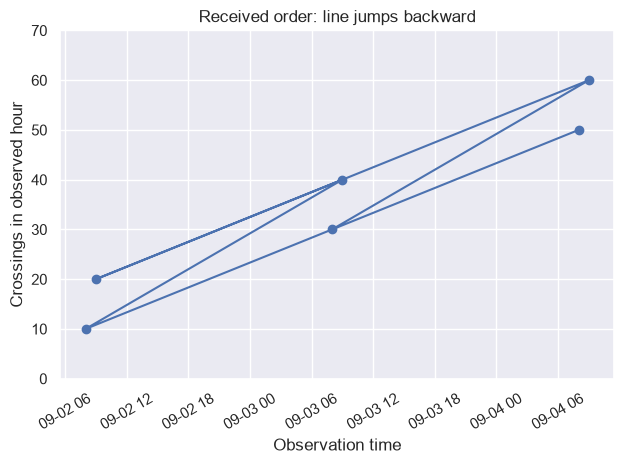

In [3]:
# Matplotlib connects these points in the supplied order.
plt.plot(unsorted_bikes.index, unsorted_bikes["Total"], marker="o")
plt.title("Received order: line jumps backward")
plt.xlabel("Observation time")
plt.ylabel("Crossings in observed hour")
plt.ylim(0, 70)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

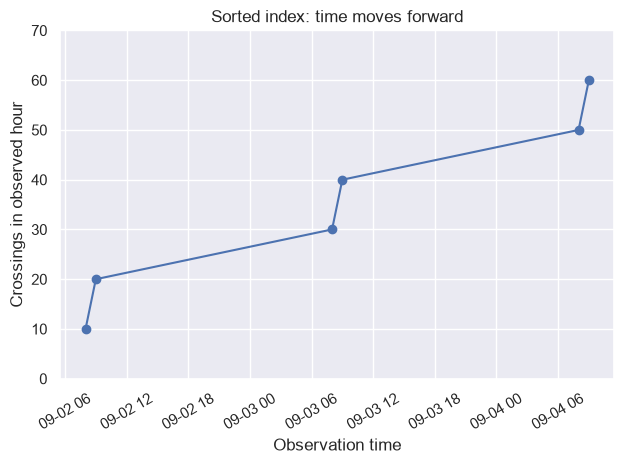

In [4]:
plt.plot(bikes.index, bikes["Total"], marker="o")
plt.title("Sorted index: time moves forward")
plt.xlabel("Observation time")
plt.ylabel("Crossings in observed hour")
plt.ylim(0, 70)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [5]:
bikes.index

DatetimeIndex(['2024-09-02 08:00:00', '2024-09-02 09:00:00',
               '2024-09-03 08:00:00', '2024-09-03 09:00:00',
               '2024-09-04 08:00:00', '2024-09-04 09:00:00'],
              dtype='datetime64[us]', name='Date', freq=None)

The whole index is a **DatetimeIndex**. Its `dtype` may display `datetime64[us]`: **`us` means microseconds**, a storage resolution, not United States date formatting. Other pandas versions may display `datetime64[ns]` for nanoseconds. One label, such as `bikes.index[0]`, is a pandas `Timestamp`. These describe the container, stored values, and a single value respectively.

`sort_index()` returns rows from earliest to latest, so we assign its result. Where does the first plot double back? Sorting by crossing counts instead would lose the chronological story.

In [6]:
print(type(bikes.index).__name__)
print(bikes.index.dtype)
print(type(bikes.index[0]).__name__)
assert bikes.index.is_monotonic_increasing

DatetimeIndex
datetime64[us]
Timestamp


### Your turn: put the delivery in order (2 minutes)

Luis wants to check the earliest and latest readings before trusting the graph. Starting with `unsorted_bikes`, make a new DataFrame called `ordered_readings` sorted by its time index. Display its first and last index labels and their `Total` counts.

Then inspect `unsorted_bikes` again. Did sorting the new DataFrame also rearrange the old one? Explain what the assignment saved.

In [7]:
# Create ordered_readings from unsorted_bikes without changing unsorted_bikes.
# Display the first and last time labels and their Total counts.

**Check your reasoning:** The earliest reading is September 2 at 08:00 with 10 crossings; the latest is September 4 at 09:00 with 60. The original delivery should still begin with September 4 at 08:00.

### Dates are values, not just text

With the readings in chronological order, Luis can ask how much time passes between them. Subtracting timestamps gives **elapsed time**, just as subtracting numbers gives their difference. `pd.Timestamp` creates a single timestamp, and the subtraction returns a `Timedelta`, a duration.

In [8]:
start = pd.Timestamp("2024-09-02 09:00:00")
end = pd.Timestamp("2024-09-03 08:00:00")
end - start

Timedelta('0 days 23:00:00')

These observations are on consecutive dates, but only **23 hours** apart. Pandas handles the change of day for us. Subtracting the original date strings would not do this: Python treats them as text.

Use dates with the year first, such as `2024-09-02`, to make examples clear. A value like `09/02/2024` can mean different dates in different date conventions. Parsing tells pandas how to interpret the text; it does not fix an ambiguous dataset description.

### Your turn: neighboring rows or elapsed time? (1 minute)

Maya says that going from one reading to the next always means one hour has passed. Use `pd.Timestamp` and subtraction to calculate these two gaps:

- September 2 at 08:00 to September 2 at 09:00.
- September 2 at 09:00 to September 3 at 08:00.

Save the durations as `same_morning_gap` and `overnight_gap`. Which part of Maya's claim does the second result challenge?

In [9]:
# Calculate same_morning_gap and overnight_gap using timestamp subtraction.

**Check your reasoning:** The gaps are 1 hour and 23 hours. Consecutive rows describe the next recorded observation, which need not be the next hour.

## Select dates with loc

Maya wants to know how September 2's morning traffic compares with the other mornings. `.loc[row, column]` lets her select readings by their time labels. A complete timestamp selects one observation in this dataset.

In [10]:
bikes.loc["2024-09-02 08:00:00", "Total"]

np.int64(10)

A less specific string selects all the timestamps that match. Predict the output type and values before running each example.

In [11]:
bikes.loc["2024-09-02"]

,East,West,Total
Date,,,
2024-09-02 08:00:00,4,6,10
2024-09-02 09:00:00,8,12,20


In [12]:
bikes.loc["2024-09", "Total"]

Date
2024-09-02 08:00:00    10
2024-09-02 09:00:00    20
2024-09-03 08:00:00    30
2024-09-03 09:00:00    40
2024-09-04 08:00:00    50
2024-09-04 09:00:00    60
Name: Total, dtype: int64

In [13]:
bikes.loc["2024-09-02":"2024-09-03", "Total"]

Date
2024-09-02 08:00:00    10
2024-09-02 09:00:00    20
2024-09-03 08:00:00    30
2024-09-03 09:00:00    40
Name: Total, dtype: int64

The first result is a `DataFrame` containing both hours on September 2. The second is a `Series` containing all six totals in September. The last includes both hours on September 2 **and** both hours on September 3: pandas label slices include the end date. A year string such as `"2024"` works the same way.

Unlike slicing a Python list with `[start:stop]`, the stopping label is included. Unlike slicing a string, these selections use the calendar meaning of the index.

**Check your understanding:** write an expression selecting just the `West` counts for September 3 through September 4. How many values should it contain?

### A runnable check for inclusive date selection

Luis needs West counts for September 3 **through** September 4. This function uses the same `.loc` rule as your expression. Its doctests check an exact timestamp, a day, a month, and both endpoints of a range. No output from the test runner means the examples passed.

In [14]:
import doctest

def select_west(data, start, stop):
    """Return West readings from start through stop, including both dates.

    >>> int(bikes.loc["2024-09-02 08:00:00", "Total"])
    10
    >>> bikes.loc["2024-09-02", "Total"].tolist()
    [10, 20]
    >>> bikes.loc["2024-09", "Total"].tolist()
    [10, 20, 30, 40, 50, 60]
    >>> select_west(bikes, "2024-09-03", "2024-09-04").tolist()
    [18, 24, 30, 36]
    """
    return data.loc[start:stop, "West"]

doctest.run_docstring_examples(select_west, globals(), verbose=False)

## Resample: group observations into time buckets

Maya wants to know how many crossings were recorded on each date. Just as `groupby("category")` groups data by matching category names, `resample("frequency")` groups time-series data into custom time buckets (like hours, days, weeks, or months) and lets us combine values or fill gaps in those periods.

We choose both a time bucket and a summary. Start with `"D"` for daily groups and `.sum()` to add the crossing counts. Later, we will compare resampling with grouping by month number and see why their group labels answer different questions.

In [15]:
daily = bikes.resample("D")["Total"].sum()
daily

Date
2024-09-02     30
2024-09-03     70
2024-09-04    110
Freq: D, Name: Total, dtype: int64

Six hourly observations have become **three** daily summaries: 10 + 20 = 30, 30 + 40 = 70, and 50 + 60 = 110. Let's make that reduction visible.

1. `bikes.resample("D")` divides time into daily intervals.
2. `["Total"]` selects the counts.
3. `.sum()` combines the counts in each interval.

Resample is **groupby for time intervals**. Each daily label is midnight at the start of its interval, not a new midnight measurement. September 2's group ends just before September 3 begins.

**Predict:** if we replace `.sum()` with `.mean()`, will September 2's answer be 30 or 15? What question would that answer?

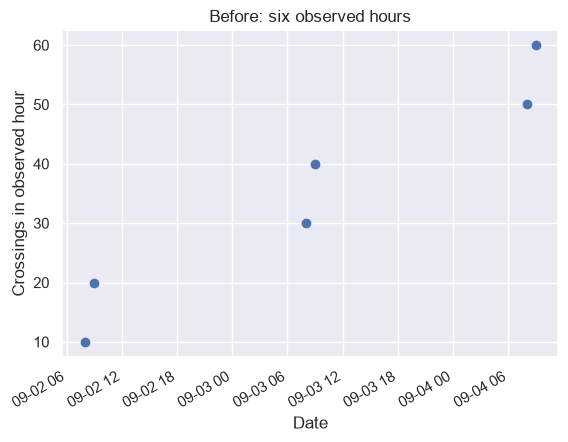

In [16]:
bikes["Total"].plot(
    marker="o", linestyle="none", title="Before: six observed hours",
    xlabel="Date", ylabel="Crossings in observed hour",
)
plt.show()

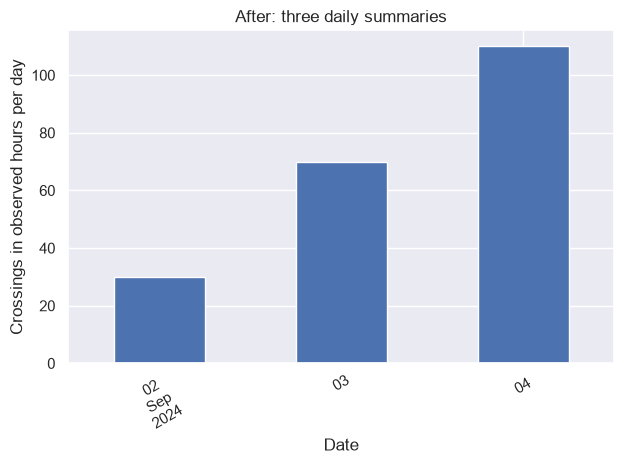

In [17]:
daily.plot.bar(
    title="After: three daily summaries", xlabel="Date",
    ylabel="Crossings in observed hours per day", rot=30,
)
plt.tight_layout()
plt.show()
assert daily.tolist() == [30, 70, 110]

In [18]:
bikes.resample("D")["Total"].mean()

Date
2024-09-02    15.0
2024-09-03    35.0
2024-09-04    55.0
Freq: D, Name: Total, dtype: float64

The result is **15 crossings per observed hour** on September 2. Adding hourly counts gives a total; averaging them gives a typical observed hour. Choosing the time interval and choosing the summary are two separate decisions.

| Time rule | Groups | Example use |
| --- | --- | --- |
| `"h"` | Hours | Hourly readings |
| `"D"` | Calendar days | Daily totals |
| `"W"` | Weeks ending Sunday | Weekly totals |
| `"MS"` | Calendar months, labeled at month start | Monthly averages |
| `"YS"` | Calendar years, labeled at year start | Annual totals |

For `"W"`, the default groups run Monday through Sunday and are labeled by Sunday. Calendar rules have different boundaries; a month is not always 30 days. We'll use `MS` and `YS` for clear start-of-period labels.

### Your turn: find the busiest observed hour each day (2 minutes)

Maya wants to know how crowded the busiest observed hour was on each date, so a daily sum alone does not answer her question. Use daily resampling to find the **maximum** hourly `Total` on each date. Save the result as `daily_peaks`, then plot it in the next cell with a title and units.

Compare it with `daily` and the daily mean above. What does each summary tell Maya, and what does each leave out?

In [19]:
# Compute daily_peaks using daily resampling and max().

In [20]:
# Plot daily_peaks with a title and units.

**Check your reasoning:** The daily peaks should be 20, 40, and 60 crossings in an observed hour. A peak describes the busiest observed hour; it does not report how many crossings occurred across both hours.

## Choose the detail that answers the question

Maya can now switch between hourly readings and daily summaries. Which view helps her plan the ride? The answer depends on whether she wants to compare hours, days, or longer periods. The **granularity** is how much time each row represents; resampling changes that level of detail.

| Question | Useful time detail | What we need |
| --- | --- | --- |
| Is 8:00 busier than 9:00? | Individual hours | Keep the hourly observations |
| How many crossings were recorded each day? | Days | Add the hourly counts within each day |
| What was a typical recorded hour each day? | Days | Average the hourly counts within each day |

Combining smaller intervals into larger ones is called **downsampling**. A main reason to downsample is to reduce short-term noise so we can see broader trends instead of every fluctuation in individual data points. Downsampling also reduces detail: from the daily total 30, we cannot recover that its two hourly counts were 10 and 20. Many different pairs add up to 30.

**Predict:** could we add hourly temperatures to find the temperature for a day? Counts of separate crossings add up meaningfully; temperatures usually call for an average, minimum, or maximum instead. A time rule chooses the groups, but the meaning of the measurement determines the summary.

### Compare consecutive summaries

The daily totals describe each date separately. Luis wants to compare one day with the next: how much did the recorded total change? A pandas `Series` provides `.diff()`, which subtracts the previous row from the current one. With a list, the same calculation would be `values[i] - values[i - 1]`.

In [21]:
daily.diff()

Date
2024-09-02     NaN
2024-09-03    40.0
2024-09-04    40.0
Freq: D, Name: Total, dtype: float64

The changes are `NaN`, **40**, and **40**. There is no earlier row to compare with the first daily total. After that, the recorded totals rose by 40 each day.

Here, neighboring rows represent consecutive days because we resampled by day. On an irregular series, `.diff()` would still compare neighboring rows, even if they were different amounts of time apart. Always check what the index means before calling a change "per day."

### Your turn: how much did the peak change? (1 minute)

Luis compares the busiest observed hour on each day rather than the whole day's recorded total. Compute those daily peaks directly from `bikes`, then use `.diff()` to compare them. Save the result as `peak_changes`.

Why is the first value missing? Does a larger daily total necessarily mean every hour got busier?

In [22]:
# Compute peak_changes from bikes without relying on your previous exercise.

**Check your reasoning:** The changes are NaN, 20, and 20. There is no previous peak for the first date. A summary of a group cannot tell us how every individual hour changed.

## Same month, different year: did January get busier?

Comparing consecutive days keeps the dates in order. But what happens when the club compares the same part of the calendar across years? Consider four daily totals from two Januaries. Maya says, “January got busier!” Luis groups by month number and sees just one number. What disappeared?

These are **invented observations of only two days per year**. They demonstrate grouping; they cannot establish that either whole January got busier.

In [23]:
january = pd.DataFrame(
    {"Total": [10, 20, 100, 200]},
    index=pd.to_datetime(["2023-01-01", "2023-01-02", "2024-01-01", "2024-01-02"]),
)
january

,Total
2023-01-01,10
2023-01-02,20
2024-01-01,100
2024-01-02,200


`index.month` extracts just a number from 1 to 12. Predict how many groups this makes.

In [24]:
january.groupby(january.index.month)["Total"].sum()

1    330
Name: Total, dtype: int64

There is one group labeled `1`, with total **330**. The year was left out of our grouping key. That answers "How many crossings were recorded in January across all years?"

Now ask for a separate result for each calendar month on the timeline.

In [25]:
january_monthly = january.resample("MS")["Total"].sum(min_count=1)
january_monthly

2023-01-01     30.0
2023-02-01      NaN
2023-03-01      NaN
2023-04-01      NaN
2023-05-01      NaN
2023-06-01      NaN
2023-07-01      NaN
2023-08-01      NaN
2023-09-01      NaN
2023-10-01      NaN
2023-11-01      NaN
2023-12-01      NaN
2024-01-01    300.0
Freq: MS, Name: Total, dtype: float64

January 2023 has **30**, while January 2024 has **300**. The months between them appear too, with missing values (`NaN`), because resampling constructs a sequence of time intervals. `min_count=1` asks for at least one non-missing observation before reporting a sum.

| Our question | Appropriate grouping |
| --- | --- |
| How did traffic change month by month over time? | `resample("MS")` keeps each year-month separate |
| What is a typical January compared with a typical July? | Group by `index.month` and use an appropriate average |

The same issue applies to week numbers: week 1 repeats each year. This is a choice of **grouping key**, not a limitation of `groupby`. For example, `groupby([january.index.year, january.index.month])` keeps the years separate too. Resampling handles calendar intervals and their date labels for us.

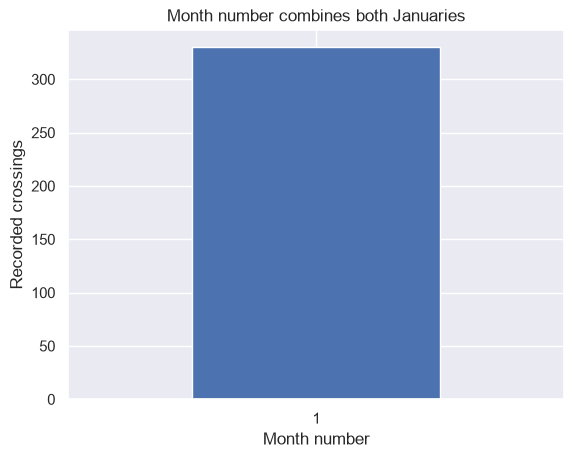

In [26]:
january.groupby(january.index.month)["Total"].sum().plot.bar(
    rot=0, title="Month number combines both Januaries",
    xlabel="Month number", ylabel="Recorded crossings",
)
plt.show()

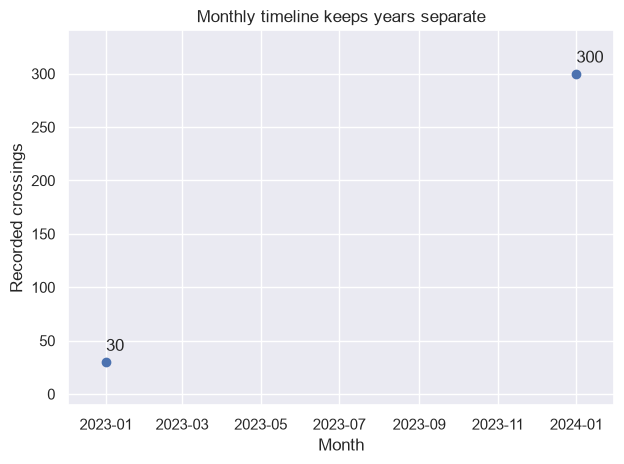

In [27]:
plt.plot(january_monthly.index, january_monthly, marker="o", linestyle="none")
plt.margins(x=0.08, y=0.15)
plt.title("Monthly timeline keeps years separate")
plt.xlabel("Month")
plt.ylabel("Recorded crossings")
for date, value in january_monthly.dropna().items():
    plt.annotate(f"{value:.0f}", (date, value), xytext=(0, 8), textcoords="offset points")
plt.tight_layout()
plt.show()
assert january_monthly.dropna().tolist() == [30, 300]
assert january_monthly.isna().sum() == 11

The timeline separates the two recorded totals: 30 in January 2023 and 300 in January 2024. The space between them is just as important. No observations were supplied for those months, so we cannot tell how traffic changed between the two Januaries.

### Your turn: keep the year in the group (2 minutes)

Luis wants a second way to keep the Januaries separate. Use `groupby` with both `january.index.year` and `january.index.month`, select `Total`, and sum. Save the result as `year_month_totals`.

Compare its groups with `january_monthly`. Why does resampling include months that this grouping does not create?

In [28]:
# Group january by a list containing the year and month arrays.

**Check your reasoning:** There should be two groups, (2023, 1) with 30 and (2024, 1) with 300. Groupby uses the keys in the observed rows; resample constructs consecutive calendar intervals, including empty months.

## Missing observations are not zero

Those empty months raise a question for Luis: if a time interval has no readings, should its total be zero? Return to Maya's three-day example and imagine the counter stopped recording for all of September 3. Remove those rows, then ask for daily totals.

In [29]:
with_gap = bikes.loc[bikes.index.day != 3]
with_gap.resample("D")["Total"].sum(min_count=1)

Date
2024-09-02     30.0
2024-09-03      NaN
2024-09-04    110.0
Freq: D, Name: Total, dtype: float64

September 3 is `NaN`, not zero. Zero would mean we measured no crossings; here we have no measurements. Without `min_count=1`, an empty group's sum would be zero and could hide the gap.

Use `isna()` to identify missing values. `dropna()` removes them; `fillna(0)` replaces them with zero. Either choice changes what your data says. Don't fill an unobserved traffic count with zero unless you have evidence that zero is correct.

One recorded hour is enough to satisfy `min_count=1`, so it does **not** guarantee a complete day. A count of valid observations helps us check coverage.

In [30]:
with_gap.resample("D")["Total"].count()

Date
2024-09-02    2
2024-09-03    0
2024-09-04    2
Freq: D, Name: Total, dtype: int64

We get **2, 0, 2** valid readings. Both `mean()` and `sum()` normally skip missing values; even a non-missing summary can be based on incomplete data. For a real hourly dataset, compare coverage with the expected readings before interpreting a daily or weekly result.

### Your turn: catch an incomplete day (2 minutes)

This time, the counter misses just September 3 at 09:00. Run the setup below, then compute daily sums with `min_count=1` as `partial_totals` and valid hourly counts as `partial_counts`.

Maya sees a non-missing daily sum and calls it a complete day. Use both results to explain why that conclusion is mistaken.

In [31]:
partial_day = bikes.loc[bikes.index != pd.Timestamp("2024-09-03 09:00:00")]
# Compute partial_totals and partial_counts without changing bikes.

**Check your reasoning:** The counts should be 2, 1, and 2. September 3 has a recorded total of 30 instead of the original 70. One valid reading satisfies min_count=1, but it does not restore the missing hour.

### More rows do not mean more measurements

A missing day is easy to spot, but we can also create gaps by asking for more detail than the counter recorded. What happens if Maya requests readings every 30 minutes when the counter recorded only each hour? That is a finer frequency, often called **upsampling**. Adding time slots cannot tell us what the sensor would have measured in between.

`.asfreq("30min")` places observations on a 30-minute grid. For this example, we first select one day's two readings.

In [32]:
bikes.loc["2024-09-02", "Total"].asfreq("30min")

Date
2024-09-02 08:00:00    10.0
2024-09-02 08:30:00     NaN
2024-09-02 09:00:00    20.0
Freq: 30min, Name: Total, dtype: float64

There are now three rows: 8:00 has **10**, 8:30 is **NaN**, and 9:00 has **20**. The middle slot is a place for a possible measurement, not a newly observed value. Guessing it would require an additional assumption.

Compare this with daily resampling: downsampling combines existing readings into summaries; creating a finer grid exposes times for which we have no reading.

### Your turn: count measurements, not time slots (1 minute)

Put September 2's `Total` readings on a 30-minute grid and save it as `half_hour_grid`. Compare `len(half_hour_grid)` with `half_hour_grid.count()`, then locate its missing value with `isna()`.

If Luis fills that missing value with zero, what would a reader incorrectly infer about 08:30?

In [33]:
# Create half_hour_grid, then compare its row count with its valid-value count.

**Check your reasoning:** There are three time slots but only two observed values. The missing 08:30 slot tells us that we have no reading there; zero would claim that the measured count was zero.

## Investigate the real bridge: which weekday is busiest on average?

The small example shows how dates, summaries, and missing readings behave. Maya is ready to ask her original planning question using [bicycles.csv](bicycles.csv): hourly East and West counts from Seattle's Fremont Bridge, covering October 2012 through March 2019.

We'll inspect **2017**, one complete calendar year in the file. How does hourly traffic look summarized by day or week, and which weekday has the highest average daily count? These are recorded crossings, so one person can appear more than once.

The file arrives newest first, using a month/day/year, 12-hour clock format. Parse that format explicitly, then sort. If either side is missing, their sum stays missing. The examples use the local files `bicycles.csv`, `seattle_air.csv`, and `earthquakes.csv` in the same folder as this notebook.

In [34]:
bicycles = pd.read_csv(
    "bicycles.csv", index_col="Date", parse_dates=["Date"],
    date_format="%m/%d/%Y %I:%M:%S %p",
)
bicycles = bicycles.sort_index()
bicycles["Total"] = bicycles["East"] + bicycles["West"]
bicycles.head()

,East,West,Total
Date,,,
2012-10-03 00:00:00,4.0,9.0,13.0
2012-10-03 01:00:00,4.0,6.0,10.0
2012-10-03 02:00:00,1.0,1.0,2.0
2012-10-03 03:00:00,2.0,3.0,5.0
2012-10-03 04:00:00,6.0,1.0,7.0


Before averaging weekdays, compare two ways of viewing the record: "What readings were recorded during March 2017?" and "How many crossings were recorded in each week?" Before running the cells, identify which one selects existing observations and which one groups and summarizes.

In [35]:
bicycles.loc["2017-03", "Total"].head()

Date
2017-03-01 00:00:00    3.0
2017-03-01 01:00:00    4.0
2017-03-01 02:00:00    2.0
2017-03-01 03:00:00    1.0
2017-03-01 04:00:00    6.0
Name: Total, dtype: float64

In [36]:
weekly = bicycles.resample("W")["Total"].sum(min_count=1)
weekly.head()

Date
2012-10-07    14292.0
2012-10-14    16795.0
2012-10-21    15509.0
2012-10-28    13437.0
2012-11-04    12194.0
Freq: W-SUN, Name: Total, dtype: float64

The first cell selects March's hourly readings and displays the first five. The second produces a `Series` with one result for each week and displays its first five results. Notice that the units changed from crossings **per hour** to crossings **per week**. We summarized the observations in every week; we did not just keep one arbitrary hour from each week.

**Discuss:** could we fairly compare the first week's total with a complete week's total? The file begins partway through a week. A calendar group can contain fewer observations at the edge of a dataset, even if none of the recorded values are missing.

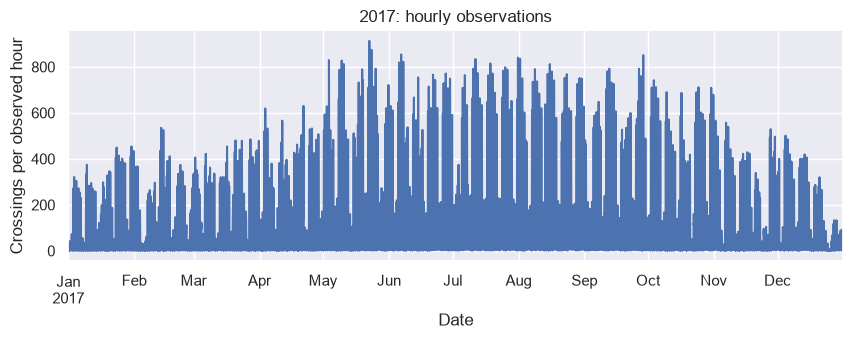

In [37]:
year_bikes = bicycles.loc["2017"]
year_daily = year_bikes["Total"].resample("D").sum(min_count=1)
year_weekly = year_bikes["Total"].resample("W").sum(min_count=1)
year_bikes["Total"].plot(
    figsize=(10, 3), title="2017: hourly observations",
    xlabel="Date", ylabel="Crossings per observed hour",
)
plt.show()

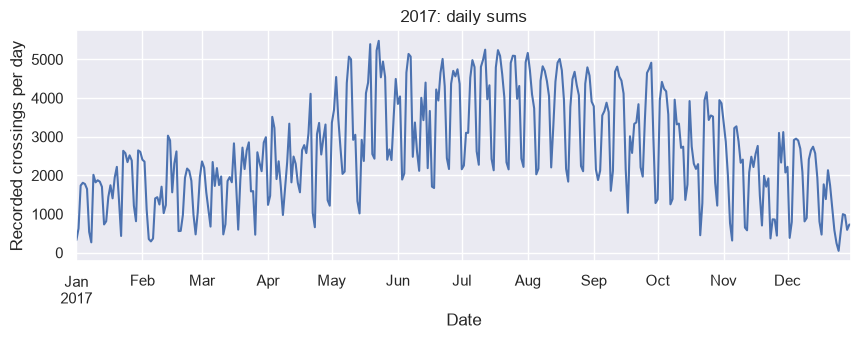

In [38]:
year_daily.plot(
    figsize=(10, 3), title="2017: daily sums",
    xlabel="Date", ylabel="Recorded crossings per day",
)
plt.show()

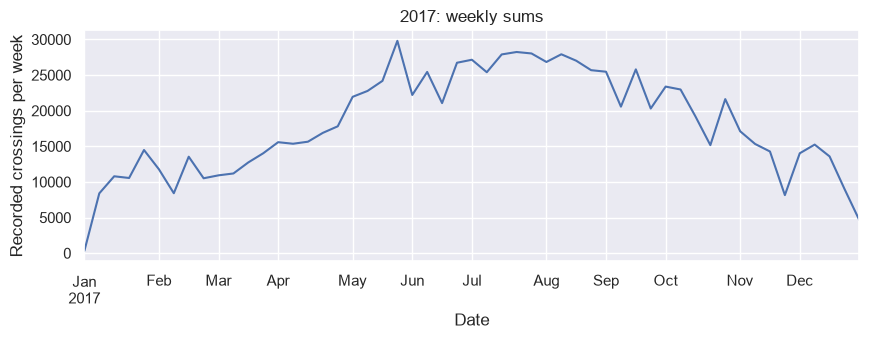

In [39]:
year_weekly.plot(
    figsize=(10, 3), title="2017: weekly sums",
    xlabel="Date", ylabel="Recorded crossings per week",
)
plt.show()

**Your turn (3 minutes):** Maya wants to know which hours are busiest within a week. Select one week in March 2017 and plot its hourly readings. Describe one pattern the weekly summary hides. Compare with a partner before the class discusses why the vertical scales differ.

In [40]:
# Select a week with .loc, then plot Total with a title and units.

### Groupby vs. resample: the same month across different years

The two-January example showed why month numbers combine years. Now apply that distinction to the full bridge record, building on the daily and weekly timelines above.

Maya wants to know how traffic changed month by month across the years. Luis wants to know which calendar months are typically busiest. Use the **whole bicycle record**, already loaded as `bicycles`, to compare three views. The summaries below are means per **observed hour**, not monthly crossing totals.

First, look at the hourly observations before combining them.

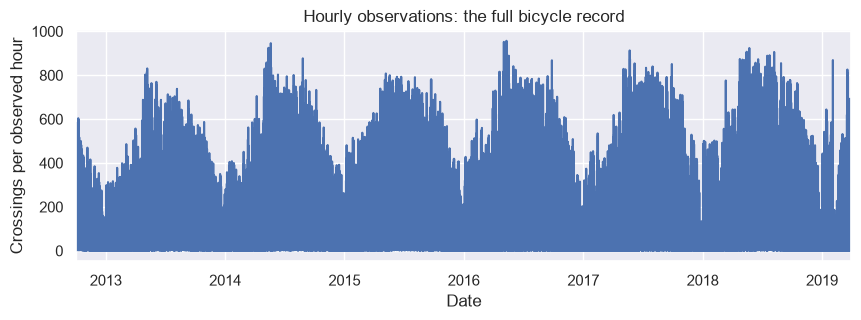

In [41]:
bicycles["Total"].plot(
    figsize=(10, 3), title="Hourly observations: the full bicycle record",
    xlabel="Date", ylabel="Crossings per observed hour",
)
plt.show()
# Notice: individual hours are noisy, but their dates still include the year.

`resample("MS")` groups readings into calendar months, labeled at each month's start. January 2013 and January 2014 remain **separate points** on the timeline. Averaging reduces hourly noise so longer changes are easier to see.

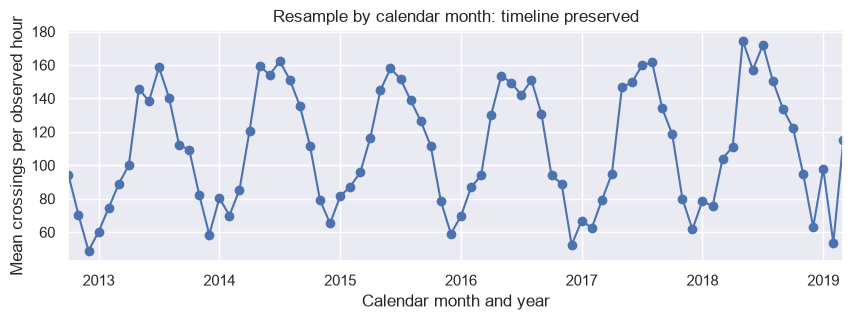

In [42]:
monthly = bicycles["Total"].resample("MS").mean()
monthly.plot(
    figsize=(10, 3), marker="o", title="Resample by calendar month: timeline preserved",
    xlabel="Calendar month and year", ylabel="Mean crossings per observed hour",
)
plt.show()
# Notice: each year-month has its own point; different years' Januaries stay separate.

`bicycles.index.month` extracts only month numbers 1 through 12. Grouping by those numbers combines **all Januaries across years**, all Februaries, and so on. Predict how many values this produces and whether its horizontal axis will still show years.

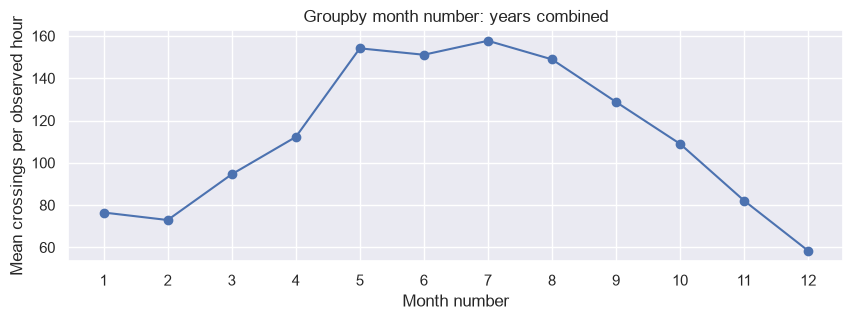

In [43]:
month_grouped = bicycles.groupby(bicycles.index.month)["Total"].mean()
month_grouped.plot(
    figsize=(10, 3), marker="o", title="Groupby month number: years combined",
    xlabel="Month number", ylabel="Mean crossings per observed hour", xticks=range(1, 13),
)
plt.show()
# Notice: there are only 12 values; each month combines its readings from every year.

The resampled graph preserves **year and month**; the month-number graph has **12 values** and no year labels. It reveals a recurring calendar pattern, but cannot tell Maya whether a particular January got busier than the previous January.

| Question | Grouping rule |
| --- | --- |
| How did recorded traffic change month by month over time? | `resample("MS")` |
| What was a typical recorded hour in each month of the year? | `groupby(bicycles.index.month)` |

The grouping key makes the difference: `groupby` could also keep years separate if we grouped by **both year and month**. Here we deliberately supply only month numbers.

**Partner check (1 minute):** which graph answers Maya's question, and which answers Luis's? Both use means, so why do they tell different stories? Unequal coverage can affect either mean; partial first and last months should not be mistaken for fully observed periods.

### From a timeline to a typical weekday

The weekly view reveals changes through the year, but Maya still needs to choose a weekday. Adding all Mondays would make the result depend on how many Mondays we observed. Instead, compute daily totals, check their valid hourly readings, then average daily totals by weekday. To compare days with the same number of readings, retain only those with 24 valid hourly counts. Local clock changes can yield 23 or 25 readings, and missing values can remove other days. This filter intentionally excludes those days rather than treating them as quiet days.

In [44]:
hour_counts = year_bikes["Total"].resample("D").count()
complete_days = year_daily.loc[hour_counts == 24]
weekday_summary = complete_days.groupby(complete_days.index.day_of_week).agg(["mean", "count"])
weekday_summary = weekday_summary.reindex(range(7))
weekday_summary.index = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary.columns = ["Mean daily crossings", "Days included"]
print("Highest observed weekday mean:", weekday_summary["Mean daily crossings"].idxmax())
weekday_summary

Highest observed weekday mean: Wednesday


,Mean daily crossings,Days included
Monday,3103.807692,52
Tuesday,3286.250000,52
Wednesday,3305.153846,52
Thursday,3074.634615,52
Friday,2919.500000,52
Saturday,1459.576923,52
Sunday,1358.750000,52


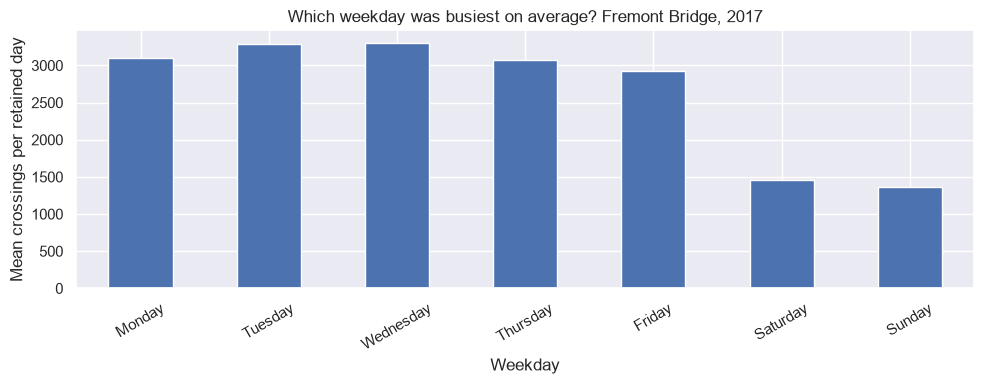

In [45]:
weekday_summary["Mean daily crossings"].plot.bar(
    figsize=(10, 4), rot=30, title="Which weekday was busiest on average? Fremont Bridge, 2017",
    xlabel="Weekday", ylabel="Mean crossings per retained day",
)
plt.tight_layout()
plt.show()

**Your turn (2 minutes):** use the chart and `Days included` to write a recommendation for Maya. State the year, bridge, and what was averaged. Would these data tell us why people crossed, or which weekday will be quietest next year? What would you ask the counter's maintainers?

## Changes and repeating patterns

Maya's weekday chart combines dates sharing a weekday; her weekly line keeps dates in sequence. These views answer different questions.

- **Trend:** a longer-term rise or fall, investigated by comparing earlier and later periods.
- **Seasonality:** a recurring calendar pattern, investigated by comparing the same weekday, month, or hour across repeated cycles.

When do crossings tend to peak within a day? Peaks may suggest commuting patterns, but the counts do not record trip purposes.

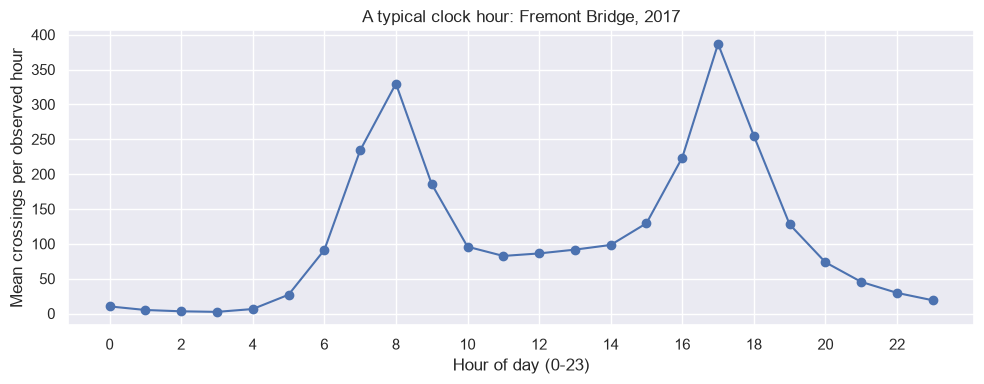

In [46]:
hourly_pattern = year_bikes.groupby(year_bikes.index.hour)["Total"].mean()
hourly_pattern.plot(
    marker="o", figsize=(10, 4), title="A typical clock hour: Fremont Bridge, 2017",
    xlabel="Hour of day (0-23)", ylabel="Mean crossings per observed hour", xticks=range(0, 24, 2),
)
plt.tight_layout()
plt.show()

The labels are hours 0–23, not dates. Each point combines the same clock hour across 2017. It shows a recurring pattern, not whether traffic increased over the years.

**Partner check:** which view helps plan a quiet hour? Which helps investigate changes between 2013 and 2018? The traffic charts help Maya choose a quieter time. Luis points out that a quiet bridge is only part of the plan: what about the air they will be breathing?

## The club's second investigation: what does an air-quality graph leave out?

To investigate air conditions, Luis opens [seattle_air.csv](seattle_air.csv), a historical snapshot from the Puget Sound Clean Air Agency's Seattle-Duwamish sensor, April 2017–April 2022. It records hourly **PM2.5**, a concentration of fine particles, in micrograms per cubic meter (µg/m³). Higher concentrations mean more particles in the air.

Maya wonders whether summer usually brings lower particle concentrations, while Luis wants to know about short periods with unusually high readings. **How do seasonal patterns and short spikes compare?** The two questions call for different views of the same measurements.

Before interpreting those views, we need to understand how the sensor works and what might interrupt its readings. The people, equipment, and collection practices behind a dataset form its **data setting**. They shape which measurements reach the table and what those measurements can tell us.

In [47]:
seattle_air = pd.read_csv("seattle_air.csv", index_col="Time", parse_dates=["Time"]).sort_index()
print(seattle_air.index)
print("Missing hourly values:", seattle_air["PM2.5"].isna().sum())
seattle_air.head()

DatetimeIndex(['2017-04-06 00:00:00', '2017-04-06 01:00:00',
               '2017-04-06 02:00:00', '2017-04-06 03:00:00',
               '2017-04-06 04:00:00', '2017-04-06 05:00:00',
               '2017-04-06 06:00:00', '2017-04-06 07:00:00',
               '2017-04-06 08:00:00', '2017-04-06 09:00:00',
               ...
               '2022-04-06 14:00:00', '2022-04-06 15:00:00',
               '2022-04-06 16:00:00', '2022-04-06 17:00:00',
               '2022-04-06 18:00:00', '2022-04-06 19:00:00',
               '2022-04-06 20:00:00', '2022-04-06 21:00:00',
               '2022-04-06 22:00:00', '2022-04-06 23:00:00'],
              dtype='datetime64[us]', name='Time', length=43848, freq=None)
Missing hourly values: 789


,PM2.5
Time,
2017-04-06 00:00:00,6.8
2017-04-06 01:00:00,5.3
2017-04-06 02:00:00,5.3
2017-04-06 03:00:00,5.6
2017-04-06 04:00:00,5.9


### Start with measurements, then change the lens

Start by checking the dates and the meaning of the values, just as we did for the bridge counter. `.loc["2022"]` selects the recorded rows from that year. The file covers only part of 2022, so yearly totals would not compare equivalent periods. PM2.5 is a concentration: summing hourly concentrations does not give a useful daily concentration. Compare daily **means** and **maxima**, with coverage alongside them.

In [48]:
seattle_air.loc["2022"]

,PM2.5
Time,
2022-01-01 00:00:00,27.2
2022-01-01 01:00:00,25.1
2022-01-01 02:00:00,23.9
2022-01-01 03:00:00,21.0
2022-01-01 04:00:00,16.7
...,...
2022-04-06 19:00:00,5.1
2022-04-06 20:00:00,5.0
2022-04-06 21:00:00,5.3


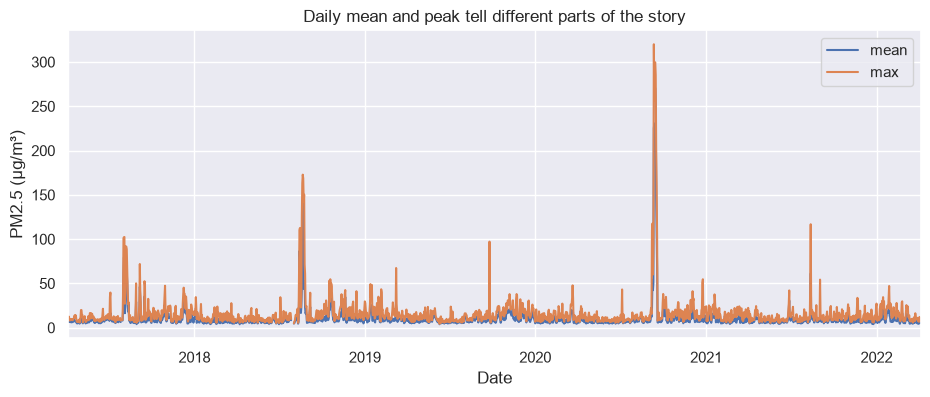

In [49]:
air_daily = seattle_air["PM2.5"].resample("D").agg(["mean", "max", "count"])
air_daily[["mean", "max"]].plot(
    figsize=(11, 4), title="Daily mean and peak tell different parts of the story",
    xlabel="Date", ylabel="PM2.5 (µg/m³)",
)
plt.show()

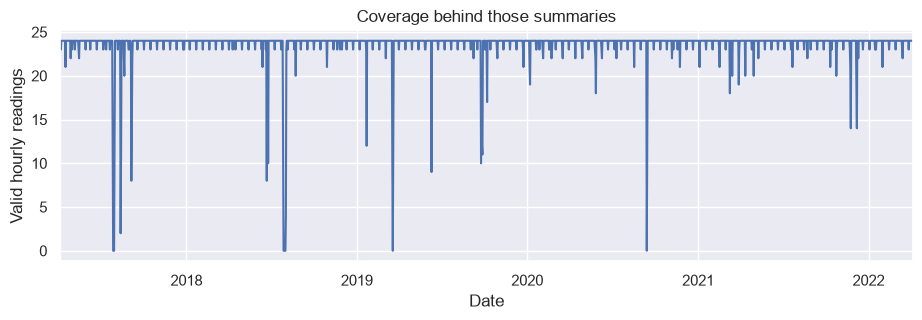

In [50]:
air_daily["count"].plot(
    figsize=(11, 3), title="Coverage behind those summaries",
    xlabel="Date", ylabel="Valid hourly readings",
)
plt.show()

**Your turn (3 minutes):** Maya wants to know whether a visible pollution peak was a short-lived spike or part of several days of high readings. Choose a visible spike, select its month with .loc, and plot the original hourly PM2.5. Describe what a monthly mean would hide. Then check the daily counts: does a low count justify calling a day clean?

In [51]:
# Select one month, plot PM2.5, and inspect its daily coverage.

### What's in a NaN? Compare observation with interpolation

The coverage plot shows that some days have fewer readings than others. Maya wants to know how filling those gaps would change the averages. **Linear interpolation** estimates a missing value from nearby observations. On an evenly spaced hourly index, ordinary linear interpolation and time-based linear interpolation agree; `method="time"` explicitly uses elapsed time.

Keep observations and estimates separate. The following calculation fills only gaps **between** observations (`limit_area="inside"`), leaving leading and trailing gaps unknown. An interior estimate can still miss a sharp smoke spike, especially across a long gap.

In [52]:
missing_values = seattle_air["PM2.5"].isna()
air_estimates = seattle_air.interpolate(method="time", limit_area="inside")
comparison = pd.DataFrame({"Observed": seattle_air["PM2.5"], "Interpolated estimate": air_estimates["PM2.5"]})
comparison.loc[missing_values].head()

,Observed,Interpolated estimate
Time,,
2017-04-07 07:00:00,NaN,10.950000
2017-04-17 06:00:00,NaN,9.466667
2017-04-17 07:00:00,NaN,8.633333
2017-04-17 09:00:00,NaN,6.800000
2017-04-28 09:00:00,NaN,6.000000


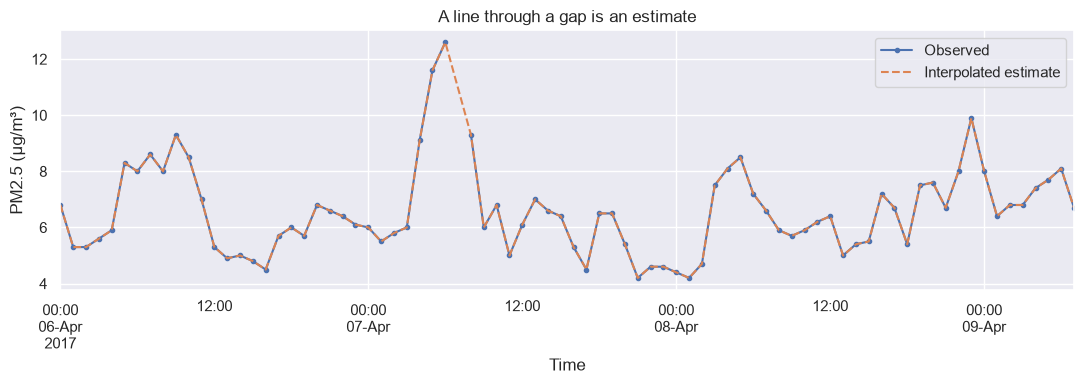

In [53]:
if missing_values.any():
    gap_time = missing_values.loc[missing_values].index[0]
    window = comparison.loc[gap_time - pd.Timedelta(days=2):gap_time + pd.Timedelta(days=2)]
    window.plot(
        figsize=(11, 4), style={"Observed": ".-", "Interpolated estimate": "--"},
        title="A line through a gap is an estimate", xlabel="Time", ylabel="PM2.5 (µg/m³)",
    )
    plt.tight_layout()
    plt.show()

### Your turn: estimate a gap by hand, then with code (3 minutes)

Suppose a sensor records 8 at 08:00 and 20 at 12:00, with a missing reading at 09:00. If the value rose at a constant rate, what would the 09:00 estimate be?

Run the setup below. Use `.interpolate(method="time")` to create `time_estimate`, then ordinary `.interpolate()` to create `row_estimate`. Compare their 09:00 values. Which method accounts for the unequal gaps between timestamps? Does either result become an observation?

In [54]:
uneven_readings = pd.Series(
    [8.0, None, 20.0],
    index=pd.to_datetime(["2024-09-02 08:00", "2024-09-02 09:00", "2024-09-02 12:00"]),
)
# Compute time_estimate and row_estimate, keeping uneven_readings unchanged.

**Check your reasoning:** The time-based estimate is 11: one quarter of the four-hour rise from 8 to 20. Ordinary linear interpolation gives 14 because the missing row is halfway between the two observed rows. Both values remain estimates.

A straight line can fill a gap on the graph, but it cannot explain why the measurement is missing. Possible causes include scheduled maintenance (such as biweekly servicing), break-ins or vandalism, lost internet connections, regulatory calibration work, or equipment relocation and upgrades. These possibilities do not establish what happened during any particular gap. Calibration also matters for recorded values: a sensor calibrated for lower concentrations may underreport high concentrations, making a peak look smaller than it was.

**Partner pause (2 minutes):** if missingness occurred during the smokiest hours, how might interpolation affect a daily mean? Write a question for the agency before filling the gap. Filling with zero would claim no particles were measured there.

Watch Yanni Loukissas discuss collection practices (7:57–10:24). Identify one human and one technical process that could change our chart. [Open the clip](https://www.youtube.com/watch?v=bUws5GCF3GI&t=477s) if the embed is unavailable.

In [55]:
%%html
<iframe width="640" height="360" src="https://www.youtube-nocookie.com/embed/bUws5GCF3GI?start=477&end=624" title="Yanni Loukissas on data settings, 7:57–10:24" allowfullscreen></iframe>

### Compare years: from separate timelines to a shared seasonal axis

Keep the original observations for the next comparison. Maya wants to know whether a high reading is part of a pattern that repeats each summer or an unusual episode in one year. Looking at each year separately is a useful first step. Select each year with `.loc`, calculate its daily means, and plot it in a separate cell. Use the same vertical limits for every plot so the peaks remain comparable.

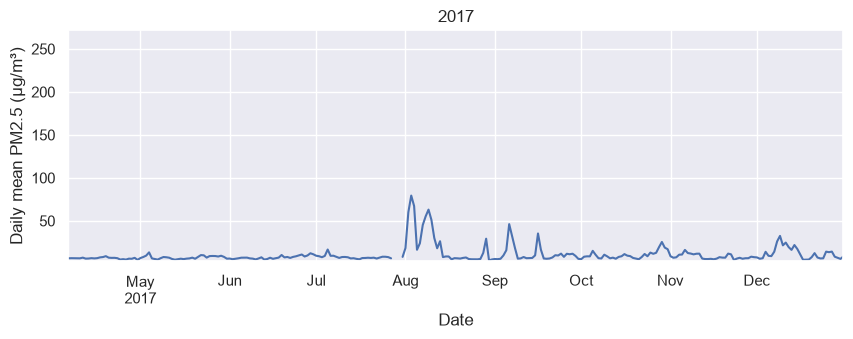

In [56]:
air_limits = (air_daily["mean"].min() - 1, air_daily["mean"].max() + 1)
seattle_air.loc["2017", "PM2.5"].resample("D").mean().plot(
    figsize=(10, 3), title="2017", ylim=air_limits,
    xlabel="Date", ylabel="Daily mean PM2.5 (µg/m³)",
)
plt.show()

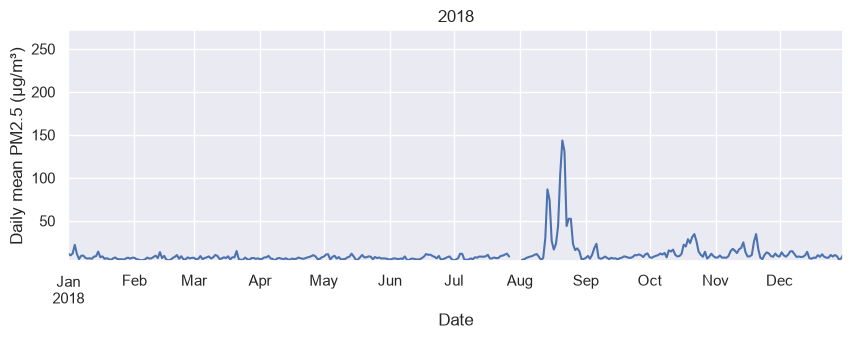

In [57]:
seattle_air.loc["2018", "PM2.5"].resample("D").mean().plot(
    figsize=(10, 3), title="2018", ylim=air_limits,
    xlabel="Date", ylabel="Daily mean PM2.5 (µg/m³)",
)
plt.show()

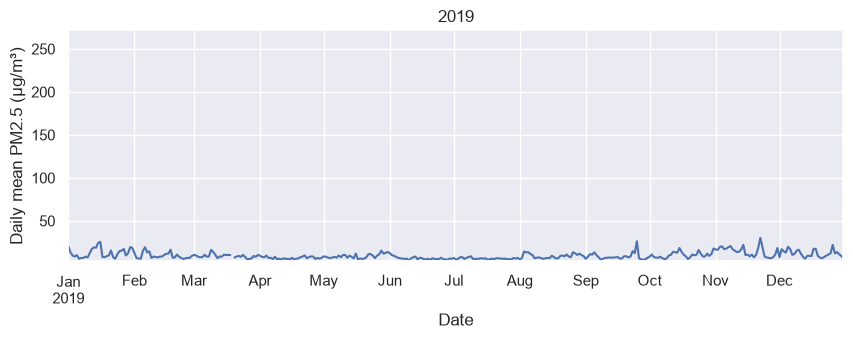

In [58]:
seattle_air.loc["2019", "PM2.5"].resample("D").mean().plot(
    figsize=(10, 3), title="2019", ylim=air_limits,
    xlabel="Date", ylabel="Daily mean PM2.5 (µg/m³)",
)
plt.show()

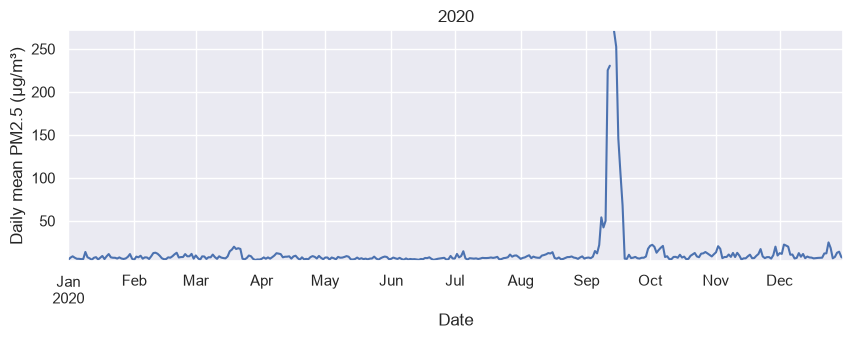

In [59]:
seattle_air.loc["2020", "PM2.5"].resample("D").mean().plot(
    figsize=(10, 3), title="2020", ylim=air_limits,
    xlabel="Date", ylabel="Daily mean PM2.5 (µg/m³)",
)
plt.show()

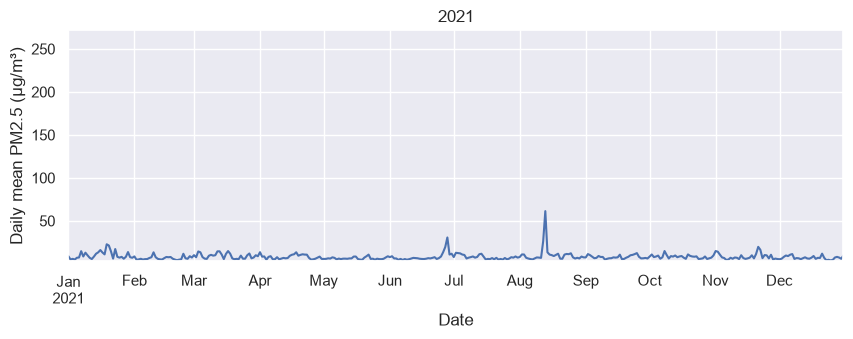

In [60]:
seattle_air.loc["2021", "PM2.5"].resample("D").mean().plot(
    figsize=(10, 3), title="2021", ylim=air_limits,
    xlabel="Date", ylabel="Daily mean PM2.5 (µg/m³)",
)
plt.show()

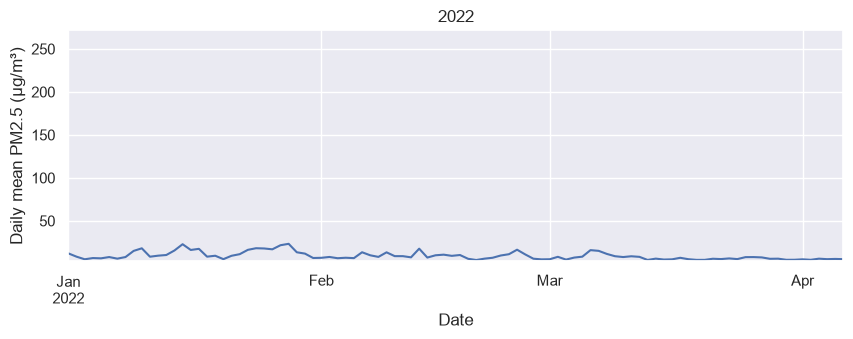

In [61]:
seattle_air.loc["2022", "PM2.5"].resample("D").mean().plot(
    figsize=(10, 3), title="2022", ylim=air_limits,
    xlabel="Date", ylabel="Daily mean PM2.5 (µg/m³)",
)
plt.show()

The separate plots make individual years visible, but Maya has to look back and forth to compare summers. An overlay would put matching parts of the calendar together. Each `DatetimeIndex` still includes a year, month, and day. To overlay seasons, choose a **shared calendar coordinate**. `index.day_of_year` returns ordinal days 1–365 (366 in leap years). That gives an approximate seasonal comparison, but after February the same number can refer to different calendar dates in leap years.

Try the day-of-year overlay first, then compare it with a monthly view to see what each makes visible.

In [62]:
seattle_air.index.day_of_year

Index([96, 96, 96, 96, 96, 96, 96, 96, 96, 96,
       ...
       96, 96, 96, 96, 96, 96, 96, 96, 96, 96],
      dtype='int32', name='Time', length=43848)

The day number gives each year a shared horizontal axis. A complete datetime label still includes a year; extracting `day_of_year` creates a separate numeric coordinate for comparing seasons. Here seaborn receives those index-derived values directly. The vertical axis uses daily means of the observed hourly readings.

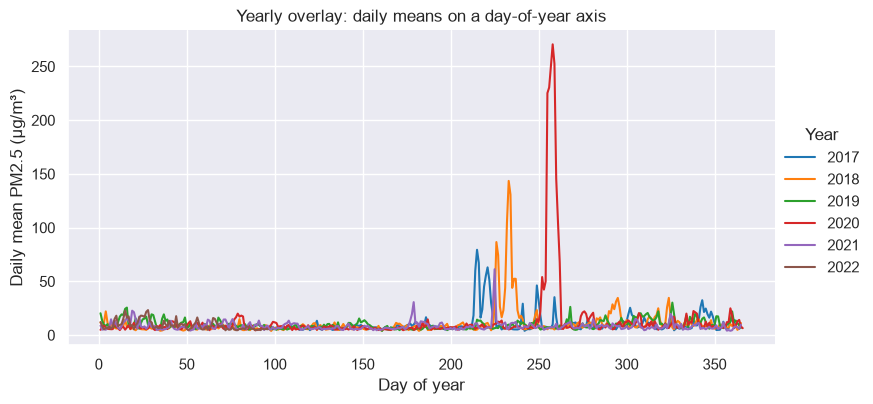

In [63]:
day_grid = sns.relplot(
    data=air_daily,
    x=air_daily.index.day_of_year,
    y="mean",
    hue=air_daily.index.year,
    palette="tab10",
    kind="line",
    errorbar=None,
    height=4,
    aspect=2,
)
day_grid.set(xlabel="Day of year", ylabel="Daily mean PM2.5 (µg/m³)",
             title="Yearly overlay: daily means on a day-of-year axis")
day_grid.legend.set(title="Year")
plt.show()

Pandas `.plot()` uses matplotlib for drawing; seaborn also uses matplotlib and adds convenient ways to map groups to colors. Here `errorbar=None` skips the calculation of uncertainty intervals. We are comparing the recorded daily means, not estimating a confidence interval.

The overlay makes short episodes easier to compare, but its calendar alignment needs a closer look before Maya compares dates across years.

### Your turn: does day 60 always mean March 1? (2 minutes)

Use the two dates below to compare March 1 in a regular year and a leap year. Extract their `.day_of_year` values and save them as `march_day_numbers`.

Why would identical day numbers misalign some calendar dates across years? After running the monthly plot below, name one benefit and one cost of using month number instead.

In [64]:
march_dates = pd.to_datetime(["2019-03-01", "2020-03-01"])
# Extract march_day_numbers, then explain what changes after February in a leap year.

**Check your reasoning:** The day numbers are 60 and 61. Month number aligns March with March in both years, but a monthly mean hides the timing and height of short daily peaks.

To compare matching calendar months, group the daily means by year and month. The next plot trades the daily overlay's detail for a clearer view of broader seasonal differences.

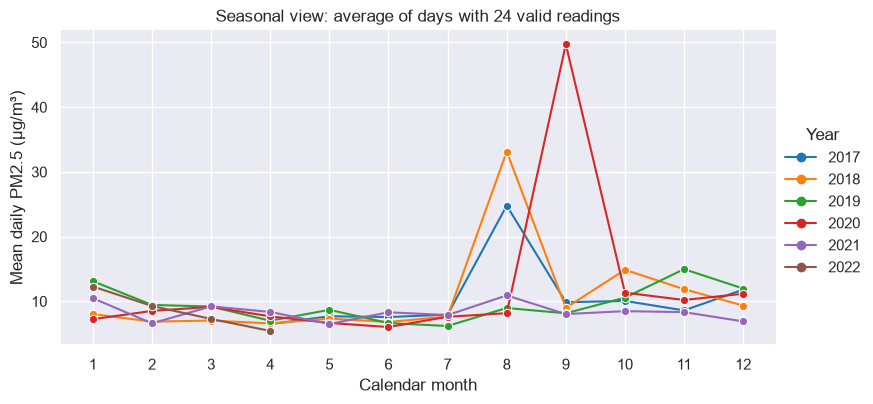

In [65]:
seasonal = air_daily.loc[air_daily["count"] == 24, ["mean"]].copy()
seasonal["Year"] = seasonal.index.year
seasonal["Month"] = seasonal.index.month
monthly_air = seasonal.groupby(["Year", "Month"], as_index=False)["mean"].mean()
grid = sns.relplot(data=monthly_air, x="Month", y="mean", hue="Year", palette="tab10",
                   kind="line", marker="o", errorbar=None, height=4, aspect=2)
grid.set(xlabel="Calendar month", ylabel="Mean daily PM2.5 (µg/m³)", xticks=range(1, 13),
         title="Seasonal view: average of days with 24 valid readings")
grid.legend.set(title="Year")
plt.show()

The shared axis makes seasons easier to compare, while averaging hides short peaks. Missing months remain absent. Excluding incomplete days can also bias the view if missingness relates to pollution. Partial first and last years still require care.

**Your turn:** write two supported observations: one from the daily peak plot and one from the seasonal plot. Give a limitation for each. Explain how both can be true, then name evidence needed to link a peak to wildfire smoke. Your choice of question and summary determines which features a reader notices. Compare your observations with [Andy Cotgreave's discussion of how data can tell multiple stories](https://www.infoworld.com/article/2246011/why-how-to-lie-with-statistics-did-us-a-disservice.html#data-can-tell-multiple-stories).

### Write a miniature datasheet before making a recommendation

The charts have given the club useful observations and several unanswered questions. How could someone record the context needed to interpret them? In [*Datasheets for Datasets*](https://arxiv.org/abs/1803.09010), Timnit Gebru and colleagues propose documenting datasets so users understand their origins and appropriate uses. Apply each category to our snapshot. Record what we know and mark unknowns as questions.

| Category | Question for this investigation |
| --- | --- |
| Motivation | Why was the dataset created, and for whom? |
| Composition | What does one row represent? Which place, dates, units, and people are represented or absent? |
| Collection process | How was the sensor installed, calibrated, and read? What could prevent a reading? |
| Preprocessing / cleaning / labeling | Were readings corrected, filtered, averaged, or interpolated before publication? |
| Uses | Which historical questions can it support? What would a current ride decision require? |
| Distribution | How is the file shared, under what terms, and with which documentation? |
| Maintenance | Who updates it, and how are corrections and sensor changes recorded? |

Even documentation cannot capture every local practice. Talking with maintainers and subject experts can reveal context absent from a table. Data are shaped by people and places even when encountered as a download.

The same questions apply beyond sensors. For a dataset about educational attainment among US adults ages 25–29, we would ask who was counted, how categories were defined, whether collection changed, and what missing values mean before interpreting a trend.

### Your turn: separate what we know from what we need (3 minutes)

Maya is ready to send the club a recommendation. Before she does, choose **three different datasheet categories** from the table. For each, write one fact supported by the file or its description, or an unanswered question if the information is unavailable.

Include a question about missing readings and a question about using this sensor to describe another location. Explain how one answer could change the club's interpretation of a chart.

In [66]:
# Write your responses as comments, using three different categories:
# Category — supported fact or unanswered question:
# Category — supported fact or unanswered question:
# Category — supported fact or unanswered question:
# How an answer could change the recommendation:

**Check your reasoning:** The file establishes the recorded place, dates, and values. It does not establish why each gap occurred or whether one sensor represents every part of a ride. A useful question identifies missing information without inventing an answer.

### Close reading with distant reading

A datasheet describes collection practices, but understanding a place can also involve listening to people who live or work there. This adds another perspective to the patterns in a chart. A plot is **distant reading**: it reveals broad patterns across observations. **Close reading** investigates particular records, collection practices, and lived experiences behind those patterns. Loukissas argues that visualization needs contextual investigation.

Watch Alvin Chang's “this is a teenager” and explore its [interactive version](https://pudding.cool/2024/03/teenagers). Identify a move from an aggregate view to an individual story. How does it change your understanding? How could we combine a traffic chart with local context without claiming one person's story represents all cyclists? [Open the video](https://www.youtube.com/watch?v=fKv1Mixv0Hk) if needed.

In [67]:
%%html
<iframe width="560" height="315" src="https://www.youtube-nocookie.com/embed/fKv1Mixv0Hk" title="Alvin Chang: this is a teenager" allowfullscreen></iframe>

After considering how individual stories and broad patterns work together, watch Loukissas's closing call to action (28:09–28:55). Write one change you would make to our investigation after hearing it. [Open the clip](https://www.youtube.com/watch?v=bUws5GCF3GI&t=1689s) if needed.

In [68]:
%%html
<iframe width="640" height="360" src="https://www.youtube-nocookie.com/embed/bUws5GCF3GI?start=1689&end=1735" title="Yanni Loukissas: closing call to action, 28:09–28:55" allowfullscreen></iframe>

### Data as a language: draft the club's recommendation

Maya and Luis now have several views of traffic and air quality, along with questions about how the measurements were collected. Their recommendation should make those choices visible. Which time window and summary support each finding? Would treating missing values differently change it? How does the collection context affect what they can conclude?

**Exit ticket:** give the club one finding about recorded bridge traffic and one about this air-quality snapshot. Cite the plot, dates, units, and summary behind each. Include an unanswered data-setting question and explain how its answer could change the recommendation. Distinguish a supported observation from an explanation still needing evidence.

## Extension: earthquake timelines

The bridge counter and air-quality sensor take readings on a schedule. To see how the same tools work when events arrive irregularly, consider earthquake records. In `earthquakes.csv`, `pd.to_datetime` combines year, month, and day columns; `set_index` makes dates the row labels.

Many earthquakes occur on the same day. Repeated date labels are allowed; resampling includes every event. Use the following prompts to compare a record of events with a record of scheduled measurements.

In [69]:
earthquakes = pd.read_csv("earthquakes.csv", index_col="id")
earthquakes["Date"] = pd.to_datetime(earthquakes[["year", "month", "day"]])
earthquakes = earthquakes.set_index("Date").sort_index()
earthquakes.head()

,year,month,day,latitude,longitude,name,magnitude
Date,,,,,,,
2016-07-27,2016,7,27,37.672333,-121.619000,California,1.43
2016-07-27,2016,7,27,21.514600,94.572100,Burma,4.90
2016-07-27,2016,7,27,37.576500,-118.859167,California,0.06
2016-07-27,2016,7,27,37.595833,-118.994833,California,0.40
2016-07-27,2016,7,27,39.377500,-119.845000,Nevada,0.30


Select all earthquakes from **August 10 through August 15, 2016**, including both endpoints. How does this compare to selecting from a hierarchical year/month/day index?

Compute the **largest magnitude on each day**. Predict whether the result is a single value, a `Series`, or a `DataFrame`.

Compute the **number of earthquakes in each week**. Use `.size()` to count rows in each group, including rows with a missing magnitude. How would `.count()` on `"magnitude"` differ?

Explain why grouping by `earthquakes.index.day` would combine unrelated dates. Write a resampling expression that keeps each day's events together without mixing months or years.

## Check your understanding

1. How are grouping earthquakes by place and resampling by day alike? What changes about group labels?
2. What does `.loc["2017-03"]` preserve that a monthly sum does not?
3. Why does grouping by `index.month` combine Januaries from different years? How did our plot reveal that?
4. Why can a small weekly sum mislead even with `min_count=1`? How did we check coverage?
5. What do `DatetimeIndex`, `Timestamp`, and `datetime64[us]` each describe? What does `us` mean?
6. What assumptions would interpolating a missing PM2.5 reading introduce?
7. How can a monthly mean and a short-lived peak support different observations? What collection context could change your interpretation?

A useful recommendation connects each claim to a time window, a meaningful summary, and an understanding of how the measurements were collected.